<a href="https://colab.research.google.com/github/raju-cse/Stock-Market-Price-Prediction/blob/main/Stock_Market_Price_Prediction_saki_sir.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import ttest_ind, f_oneway
import os

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#https://www.kaggle.com/datasets/arashnic/time-series-forecasting-with-yahoo-stock-price
df = pd.read_csv("/content/drive/MyDrive/Data_Mining/yahoo_stock.csv")
df.head()


,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


In [ ]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
# Set Date as index
df.set_index('Date', inplace=True)

In [ ]:
# EDA: Check for missing values
print("Missing values:\n", df.isnull().sum())


Missing values:
 High         0
Low          0
Open         0
Close        0
Volume       0
Adj Close    0
dtype: int64


In [ ]:
# EDA: Descriptive statistics
df.describe()

,High,Low,Open,Close,Volume,Adj Close
count,1825.000000,1825.000000,1825.000000,1825.000000,1.825000e+03,1825.000000
mean,2660.718673,2632.817580,2647.704751,2647.856284,3.869627e+09,2647.856284
std,409.680853,404.310068,407.169994,407.301177,1.087593e+09,407.301177
min,1847.000000,1810.099976,1833.400024,1829.079956,1.296540e+09,1829.079956
25%,2348.350098,2322.250000,2341.979980,2328.949951,3.257950e+09,2328.949951
50%,2696.250000,2667.840088,2685.489990,2683.340088,3.609740e+09,2683.340088
75%,2930.790039,2900.709961,2913.860107,2917.520020,4.142850e+09,2917.520020
max,3645.989990,3600.159912,3612.090088,3626.909912,9.044690e+09,3626.909912


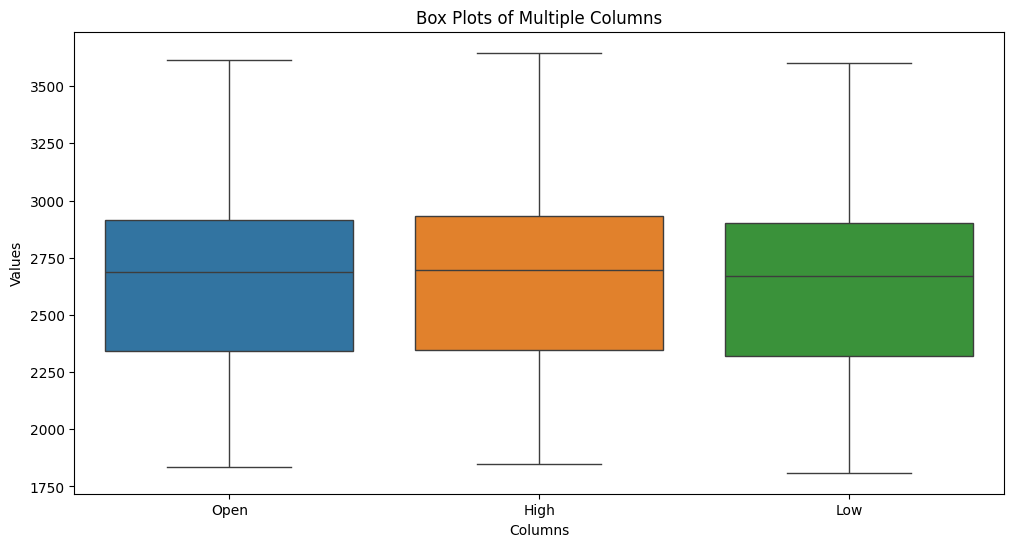

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming the dataset is loaded as 'df'
# Replace with the actual column names from your DataFrame 'df'
columns_to_plot = ['Open', 'High', 'Low']

plt.figure(figsize=(12, 6))
# Use Seaborn's boxplot with a melted DataFrame for multiple columns
sns.boxplot(data=df[columns_to_plot])

plt.title('Box Plots of Multiple Columns')
plt.xlabel('Columns')
plt.ylabel('Values')
plt.show()

In [ ]:
# EDA: Composition
# Plotting closing price over time
fig = px.line(df, x=df.index, y='Close', title='Closing Price Over Time')
fig.update_layout(title_text='Closing Price Over Time', title_x=0.5, template='plotly_dark')
fig.show()

In [ ]:
# EDA: Distribution
fig = make_subplots(rows=3, cols=2, subplot_titles=('Close', 'Volume', 'Open', 'High', 'Low', 'Adj Close'))
fig.add_trace(go.Histogram(x=df['Close'], name='Close'), row=1, col=1)
fig.add_trace(go.Histogram(x=df['Volume'], name='Volume'), row=1, col=2)
fig.add_trace(go.Histogram(x=df['Open'], name='Open'), row=2, col=1)
fig.add_trace(go.Histogram(x=df['High'], name='High'), row=2, col=2)
fig.add_trace(go.Histogram(x=df['Low'], name='Low'), row=3, col=1)
fig.add_trace(go.Histogram(x=df['Adj Close'], name='Adj Close'), row=3, col=2)
fig.update_layout(title_text='Distribution of Features', title_x=0.5, template='plotly_dark')
fig.show()

In [ ]:
# EDA: Relationship
fig = px.scatter_matrix(df, dimensions=['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], title='Scatter Matrix')
fig.update_layout(title_text='Scatter Matrix', title_x=0.5, template='plotly_dark')
fig.show()


In [ ]:
# EDA: Comparison
# Correlation matrix
correlation = df.corr()
fig = px.imshow(correlation, text_auto=True, title='Correlation Matrix')
fig.update_layout(title_text='Correlation Matrix', title_x=0.5, template='plotly_dark')
fig.show()

In [ ]:
# Statistical Tests
# T-test comparing 'High' and 'Low' prices
t_stat, p_value = ttest_ind(df['High'], df['Low'])
t_test_result = {
    'Statistic': [t_stat],
    'p-value': [p_value]
}
t_test_df = pd.DataFrame(t_test_result)
t_test_df

,Statistic,p-value
0,2.070802,0.038447


In [ ]:
# Display T-test result
fig = px.bar(t_test_df, x=t_test_df.index, y=['Statistic', 'p-value'], barmode='group', title='T-test Result: High vs Low Prices')
fig.update_layout(title_text='T-test Result: High vs Low Prices', title_x=0.5, template='plotly_dark')
fig.show()

In [ ]:
# ANOVA test for 'Open', 'High', 'Low', 'Close' prices
anova_stat, anova_p_value = f_oneway(df['Open'], df['High'], df['Low'], df['Close'])
anova_result = {
    'Statistic': [anova_stat],
    'p-value': [anova_p_value]
}
anova_df = pd.DataFrame(anova_result)
anova_df

,Statistic,p-value
0,1.432399,0.231203


In [ ]:
# Display ANOVA result
fig = px.bar(anova_df, x=anova_df.index, y=['Statistic', 'p-value'], barmode='group', title='ANOVA Test Result: Open, High, Low, Close Prices')
fig.update_layout(title_text='ANOVA Test Result: Open, High, Low, Close Prices', title_x=0.5, template='plotly_dark')
fig.show()

In [ ]:
# Data preprocessing: Feature scaling
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['Close'].values.reshape(-1, 1))

In [ ]:
# Prepare the data for LSTM
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        a = data[i:(i + time_step), 0]
        X.append(a)
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

# Define time step
time_step = 60

In [ ]:
# Create training and test sets
train_size = int(len(scaled_data) * 0.8)
test_size = len(scaled_data) - train_size
train_data, test_data = scaled_data[0:train_size, :], scaled_data[train_size:len(scaled_data), :]

In [ ]:
# Create dataset for LSTM
X_train, y_train = create_dataset(train_data, time_step)
X_test, y_test = create_dataset(test_data, time_step)

In [ ]:
# Reshape input to be [samples, time steps, features] which is required for LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [ ]:
# Build the LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(time_step, 1)))
model.add(Dropout(0.2))
model.add(LSTM(50, return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(50))
model.add(Dropout(0.2))
model.add(Dense(25))
model.add(Dense(1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [ ]:

# Train the model
history = model.fit(X_train, y_train, batch_size=1, epochs=10)

Epoch 1/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - loss: 0.0054
Epoch 2/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - loss: 0.0014
Epoch 3/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.0015
Epoch 4/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.0013
Epoch 5/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.0013
Epoch 6/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 0.0012
Epoch 7/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - loss: 0.0010
Epoch 8/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - loss: 0.0010
Epoch 9/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 9.6248e-04
Epoch 10/10
1399/1399 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.0011


In [ ]:
# Predictions
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [ ]:
# Inverse transform to get actual values
train_predict = scaler.inverse_transform(train_predict)
test_predict = scaler.inverse_transform(test_predict)
y_train = scaler.inverse_transform([y_train])
y_test = scaler.inverse_transform([y_test])

In [ ]:
# Calculate RMSE and MAE
train_rmse = np.sqrt(mean_squared_error(y_train[0], train_predict[:, 0]))
train_mae = mean_absolute_error(y_train[0], train_predict[:, 0])
test_rmse = np.sqrt(mean_squared_error(y_test[0], test_predict[:, 0]))
test_mae = mean_absolute_error(y_test[0], test_predict[:, 0])

print(f'Train RMSE: {train_rmse}, Train MAE: {train_mae}')
print(f'Test RMSE: {test_rmse}, Test MAE: {test_mae}')

Train RMSE: 26.076016065817527, Train MAE: 18.96201021795702
Test RMSE: 64.1282520864784, Test MAE: 42.882658305921055


In [ ]:
# Plotting the results
train_data_len = len(train_data)

train_plot = np.empty_like(scaled_data)
train_plot[:, :] = np.nan
train_plot[time_step:len(train_predict)+time_step, :] = train_predict

test_plot = np.empty_like(scaled_data)
test_plot[:, :] = np.nan
test_plot[len(train_predict)+(time_step*2)+1:len(scaled_data)-1, :] = test_predict

In [ ]:
# Create plot
fig = go.Figure()
fig.add_trace(go.Scatter(x=df.index, y=df['Close'], mode='lines', name='Actual Price', line=dict(color='blue')))
fig.add_trace(go.Scatter(x=df.index, y=train_plot[:, 0], mode='lines', name='Train Predict', line=dict(color='green')))
fig.add_trace(go.Scatter(x=df.index, y=test_plot[:, 0], mode='lines', name='Test Predict', line=dict(color='red')))
fig.update_layout(title='Stock Price Prediction',
                   xaxis_title='Date',
                   yaxis_title='Stock Price',
                   template='plotly_dark')
fig.show()

In [ ]:
def predict_future(model, data, scaler, time_step=60, future_steps=30):
    # Prepare the input data for Future price prediction
    last_data = data[-time_step:]
    last_data = last_data.reshape(1, time_step, 1)

    # Predict future prices
    future_predictions = []
    for _ in range(future_steps):
        next_pred = model.predict(last_data)
        future_predictions.append(next_pred[0, 0])
        last_data = np.append(last_data[:, 1:, :], [[[next_pred[0, 0]]]], axis=1)

    # Inverse transform the predictions to get actual values
    future_predictions = np.array(future_predictions).reshape(-1, 1)
    future_predictions = scaler.inverse_transform(future_predictions)

    return future_predictions

# Example usage
future_steps = 30
future_predictions = predict_future(model, scaled_data, scaler, time_step, future_steps)

# Create future dates for plotting
last_date = df.index[-1]
future_dates = pd.date_range(start=last_date, periods=future_steps + 1, inclusive='right')

# Plotting future predictions
fig = go.Figure()
fig.add_trace(go.Scatter(x=df.index, y=df['Close'], mode='lines', name='Actual Price', line=dict(color='blue')))
fig.add_trace(go.Scatter(x=future_dates, y=future_predictions[:, 0], mode='lines', name='Future Predict', line=dict(color='orange')))
fig.update_layout(title='Future Stock Price Prediction',
                   xaxis_title='Date',
                   yaxis_title='Stock Price',
                   template='plotly_dark')
fig.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━